# Setup

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


import torch
from torch import optim
from torch import nn
from torch.utils.data import DataLoader
from tqdm import tqdm

import torchvision

import torch.nn.functional as F
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torchmetrics.functional.regression import concordance_corrcoef

In [8]:
device = None

if torch.backends.mps.is_available():
    device = torch.device("mps")
    x = torch.ones(1, device=device)
else:
    device = torch.device("cpu")
    print ("MPS device not found.")

# Model

In [9]:
class AudioCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)

        self.batch_norm1 = nn.BatchNorm2d(16)
        self.batch_norm2 = nn.BatchNorm2d(32)
        self.batch_norm3 = nn.BatchNorm2d(64)

        self.pool = nn.MaxPool2d(2, 2)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 3))

        # Classification-specific layers
        self.classifier = nn.Sequential(
            nn.Linear(64 * 4 * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 4)
        )

        # Regression-specific layers
        self.regressor = nn.Sequential(
            nn.Linear(64 * 4 * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU()
        )

        self.valence_head = nn.Linear(64, 1)
        self.arousal_head = nn.Linear(64, 1)

    def forward(self, x):
        x = self.pool(F.relu(self.batch_norm1(self.conv1(x))))
        x = self.pool(F.relu(self.batch_norm2(self.conv2(x))))
        x = self.pool(F.relu(self.batch_norm3(self.conv3(x))))
        
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)

        emotion = self.classifier(x)

        regression_features = self.regressor(x)
        valence = self.valence_head(regression_features)
        arousal = self.arousal_head(regression_features)

        return emotion, valence, arousal

# Data Loading

In [10]:
from enum import Enum
class Emotion(Enum):
    HAPPY = 1
    ANGRY = 2
    SAD = 3
    FEAR = 4
    SURPRISE = 5
    NEUTRAL = 6
    FRUSTRATION = 7
    EXCITEMENT = 8

In [11]:
import librosa
from torch.utils.data import Dataset

class AudioDataset(Dataset):
    
    def __init__(self, dataframe, sr=22050, duration=5.0):
        self.dataframe = dataframe
        self.sr = sr
        self.duration = duration

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        
        audio_path = row['wave_file']
        start_time = float(row['start_time'])
        end_time = float(row['end_time'])
        
        try:
            y, sr = librosa.load(audio_path, sr=self.sr)
            start_sample = int(start_time * sr)
            end_sample = int(end_time * sr)
            segment = y[start_sample:end_sample]
            
            #pad or truncate to maintain same dimensions
            if self.duration is not None:
                target_samples = int(self.duration * sr)
                if len(segment) < target_samples:
                    padding = target_samples - len(segment)
                    segment = np.pad(segment, (0, padding), mode='constant')
                else:
                    segment = segment[:target_samples]
                    
            mel_spectrogram = librosa.feature.melspectrogram(y=segment, sr=sr, n_mels=128)
            mel_spectrogram_db = librosa.power_to_db(mel_spectrogram, ref=np.max)
            
            mel_spectrogram_db = (mel_spectrogram_db - mel_spectrogram_db.mean()) / (mel_spectrogram_db.std() + 1e-8)
            mel_spectrogram_db = np.expand_dims(mel_spectrogram_db, axis=0)
        except Exception as e:
            print(f"Error loading {audio_path}: {e}")
            mel_spectrogram_db = np.zeros((1, 128, 216))

        emotion = int(row['emotion'])
        valence = float(row['valence'])
        arousal = float(row['arousal'])
        
        return {
            'mel_spectrogram': torch.FloatTensor(mel_spectrogram_db),
            'emotion': torch.LongTensor([emotion]),
            'valence': torch.FloatTensor([valence]),
            'arousal': torch.FloatTensor([arousal])
        }

In [12]:

dataset = pd.read_csv("IEMOCAP_dataset.csv")

# drop all fear and surprise and frustration
dataset = dataset[(dataset['emotion'] != Emotion.FEAR.value) & (dataset['emotion'] != Emotion.SURPRISE.value) & (dataset['emotion'] != Emotion.FRUSTRATION.value)]
# replace excited with happy
dataset['emotion'] = dataset['emotion'].replace({Emotion.EXCITEMENT.value : Emotion.HAPPY.value})


from sklearn.model_selection import train_test_split
train_data, test_dataset = train_test_split(dataset, test_size=0.2, random_state=42)
train_dataset, val_dataset = train_test_split(train_data, test_size=0.2, random_state=42)

train_dataset_obj = AudioDataset(train_dataset, sr=22050, duration=5.0)  # 5 second clips
val_dataset_obj = AudioDataset(val_dataset, sr=22050, duration=5.0)
test_dataset_obj = AudioDataset(test_dataset, sr=22050, duration=5.0)

In [13]:
print(train_dataset_obj.dataframe['emotion'].value_counts())

print(val_dataset_obj.dataframe['emotion'].value_counts())

print(test_dataset_obj.dataframe['emotion'].value_counts())

emotion
6    1102
1    1036
2     701
3     700
Name: count, dtype: int64
emotion
1    274
6    267
2    175
3    169
Name: count, dtype: int64
emotion
6    339
1    326
2    227
3    215
Name: count, dtype: int64


# Train and Validate

Hyperparameters

In [14]:
batch_size = 64
lr = 1e-4
num_epochs = 25

from sklearn.utils.class_weight import compute_class_weight
class_weights = compute_class_weight('balanced', classes=np.unique(train_dataset_obj.dataframe['emotion']), y=train_dataset_obj.dataframe['emotion'])
class_weights = torch.tensor(class_weights, dtype=torch.float)

train_losses = []
val_losses = []
emotion_accuracies = []
valence_accuracies = []
arousal_accuracies = []
valence_cccs = []
arousal_cccs = []

Epoch

In [15]:
def train(model, train_loader, optimizer, device):
    model.train()
    total_loss = 0
    
    emotion_criterion = nn.CrossEntropyLoss(weight=class_weights)  
    regression_criterion = nn.MSELoss()         
    
    for batch in train_loader:
        
        mel_specs = batch['mel_spectrogram'].to(device)
        emotions = batch['emotion'].squeeze().to(device)
        valences = batch['valence'].to(device)
        arousals = batch['arousal'].to(device)
        emotion_criterion = emotion_criterion.to(device)
        regression_criterion = regression_criterion.to(device)
        
        # Forward pass
        pred_emotion, pred_valence, pred_arousal = model(mel_specs)
        
        # Calculate loss
        emotion_loss = emotion_criterion(pred_emotion, emotions)
        valence_loss = regression_criterion(pred_valence, valences)
        arousal_loss = regression_criterion(pred_arousal, arousals)
        
        loss = emotion_loss + 0.5 * valence_loss + 0.5 * arousal_loss
        
        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    return total_loss / len(train_loader)

In [16]:
def validate(model, val_loader, device, acc_threshold=0.1, test=False):
    model.eval()
    
    total_loss = 0
    emotion_correct = 0
    valence_correct = 0
    arousal_correct = 0
    
    emotion_criterion = nn.CrossEntropyLoss(weight=class_weights) 
    regression_criterion = nn.MSELoss()   
    
    valence_preds = []
    valence_targets = []
    arousal_preds = []
    arousal_targets = []
    
    with torch.no_grad():
        for batch in val_loader:
            mel_specs = batch['mel_spectrogram'].to(device)
            emotions = batch['emotion'].squeeze().to(device)
            valences = batch['valence'].to(device)
            arousals = batch['arousal'].to(device)
            emotion_criterion = emotion_criterion.to(device)
            regression_criterion = regression_criterion.to(device)
            
            pred_emotion, pred_valence, pred_arousal = model(mel_specs)
            
            emotion_loss = emotion_criterion(pred_emotion, emotions)
            valence_loss = regression_criterion(pred_valence, valences)
            arousal_loss = regression_criterion(pred_arousal, arousals)
            
            loss = emotion_loss + 0.5 * valence_loss + 0.5 * arousal_loss
            total_loss += loss.item()
            
            # emotion accuracy
            _, predicted_emotions = torch.max(pred_emotion.data, 1)
            emotion_correct += (predicted_emotions == emotions).sum().item()

            # valence accuracy
            valence_correct += (torch.abs(pred_valence - valences) < acc_threshold).sum().item()
            valence_preds.append(pred_valence)
            valence_targets.append(valences)

            # arousal accuracy
            arousal_correct += (torch.abs(pred_arousal - arousals) < acc_threshold).sum().item()
            arousal_preds.append(pred_arousal)
            arousal_targets.append(arousals)
            
    avg_loss = total_loss / len(val_loader)
    
    emotion_accuracy = emotion_correct / (len(val_loader.dataset))
    valence_accuracy = valence_correct / (len(val_loader.dataset))
    arousal_accuracy = arousal_correct / (len(val_loader.dataset))
    
    valence_ccc = concordance_corrcoef(torch.cat(valence_preds), torch.cat(valence_targets)).item()
    arousal_ccc = concordance_corrcoef(torch.cat(arousal_preds), torch.cat(arousal_targets)).item()
    
    # accuracy per emotion class for test
    if test:
        print("Accuracy per emotion class:")
        for i in [Emotion.HAPPY.value, Emotion.SAD.value, Emotion.ANGRY.value, Emotion.NEUTRAL.value]:
            class_correct = 0
            class_total = 0
            for batch in val_loader:
                emotions = batch['emotion'].squeeze().to(device)
                pred_emotion, _, _ = model(batch['mel_spectrogram'].to(device))
                _, predicted_emotions = torch.max(pred_emotion.data, 1)
                class_correct += ((predicted_emotions == emotions) & (emotions == i)).sum().item()
                class_total += (emotions == i).sum().item()
            
            print(f"Accuracy for emotion class {Emotion(i).name}: {class_correct / class_total if class_total > 0 else 0:.4f}")
    
    return avg_loss, emotion_accuracy, valence_accuracy, arousal_accuracy, valence_ccc, arousal_ccc

Training Loop

In [17]:

train_loader = DataLoader(train_dataset_obj, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset_obj, batch_size=batch_size, shuffle=False)

model = AudioCNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

best_epoch = 0
best_loss = float('inf')

for epoch in range(num_epochs):
    train_loss = train(model, train_loader, optimizer, device)
    val_loss, val_emotion_accuracy, val_valence_accuracy, val_arousal_accuracy, val_valence_ccc, val_arousal_ccc = validate(model, val_loader, device)
    
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    emotion_accuracies.append(val_emotion_accuracy)
    valence_accuracies.append(val_valence_accuracy)
    arousal_accuracies.append(val_arousal_accuracy)
    valence_cccs.append(val_valence_ccc)
    arousal_cccs.append(val_arousal_ccc)
    
    print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Val Emotion Accuracy: {val_emotion_accuracy:.4f}, Val Valence Accuracy: {val_valence_accuracy:.4f}, Val Arousal Accuracy: {val_arousal_accuracy:.4f}, Val Valence CCC: {val_valence_ccc:.4f}, Val Arousal CCC: {val_arousal_ccc:.4f}")
    
    if val_loss < best_loss:
        best_loss = val_loss
        best_epoch = epoch
        torch.save(model.state_dict(), 'audio_cnn_model.pth')
    
print("Done!")
print(f"Best Epoch: {best_epoch+1}, Best Loss: {best_loss:.4f}")
    

Epoch [1/25], Train Loss: 1.2758, Val Loss: 1.0587, Val Emotion Accuracy: 0.3096, Val Valence Accuracy: 0.2881, Val Arousal Accuracy: 0.4599, Val Valence CCC: 0.0305, Val Arousal CCC: 0.4312
Epoch [2/25], Train Loss: 1.0337, Val Loss: 0.9474, Val Emotion Accuracy: 0.3910, Val Valence Accuracy: 0.3085, Val Arousal Accuracy: 0.4893, Val Valence CCC: 0.0161, Val Arousal CCC: 0.5317
Epoch [3/25], Train Loss: 0.9457, Val Loss: 0.8907, Val Emotion Accuracy: 0.4011, Val Valence Accuracy: 0.3006, Val Arousal Accuracy: 0.4859, Val Valence CCC: 0.0372, Val Arousal CCC: 0.5401
Epoch [4/25], Train Loss: 0.8765, Val Loss: 0.8406, Val Emotion Accuracy: 0.4316, Val Valence Accuracy: 0.2463, Val Arousal Accuracy: 0.5006, Val Valence CCC: 0.0263, Val Arousal CCC: 0.5590
Epoch [5/25], Train Loss: 0.8437, Val Loss: 0.8284, Val Emotion Accuracy: 0.4441, Val Valence Accuracy: 0.3243, Val Arousal Accuracy: 0.4972, Val Valence CCC: 0.0511, Val Arousal CCC: 0.5597
Epoch [6/25], Train Loss: 0.8236, Val Loss: 0

# Test

In [18]:
test_loader = DataLoader(test_dataset_obj, batch_size=batch_size, shuffle=False)

# test best epoch instead of last epoch
model.load_state_dict(torch.load('audio_cnn_model.pth'))
test_loss, test_emotion_accuracy, test_valence_accuracy, test_arousal_accuracy, test_valence_ccc, test_arousal_ccc = validate(model, test_loader, device, test=True)
print(f"Test Loss: {test_loss:.4f}, Test Emotion Accuracy: {test_emotion_accuracy:.4f}, Test Valence Accuracy: {test_valence_accuracy:.4f}, Test Arousal Accuracy: {test_arousal_accuracy:.4f}, Test Valence CCC: {test_valence_ccc:.4f}, Test Arousal CCC: {test_arousal_ccc:.4f}")

Accuracy per emotion class:
Accuracy for emotion class HAPPY: 0.6687
Accuracy for emotion class SAD: 0.6837
Accuracy for emotion class ANGRY: 0.7048
Accuracy for emotion class NEUTRAL: 0.0000
Test Loss: 0.7455, Test Emotion Accuracy: 0.4743, Test Valence Accuracy: 0.3514, Test Arousal Accuracy: 0.5357, Test Valence CCC: 0.2489, Test Arousal CCC: 0.6283


# Plot

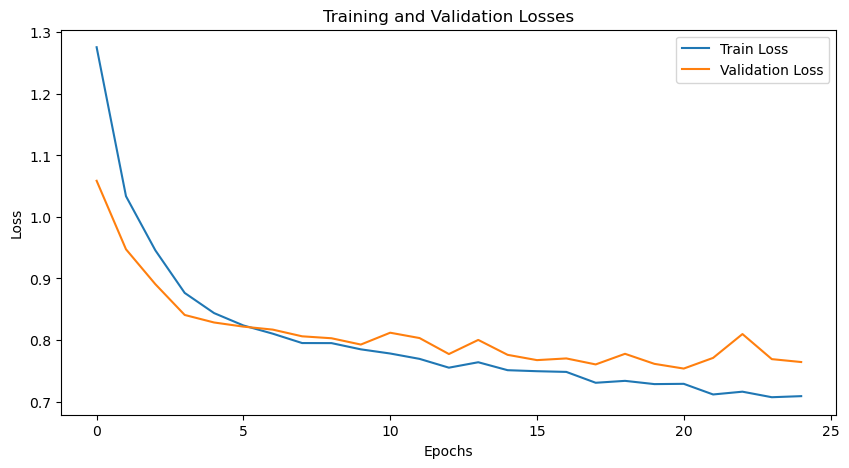

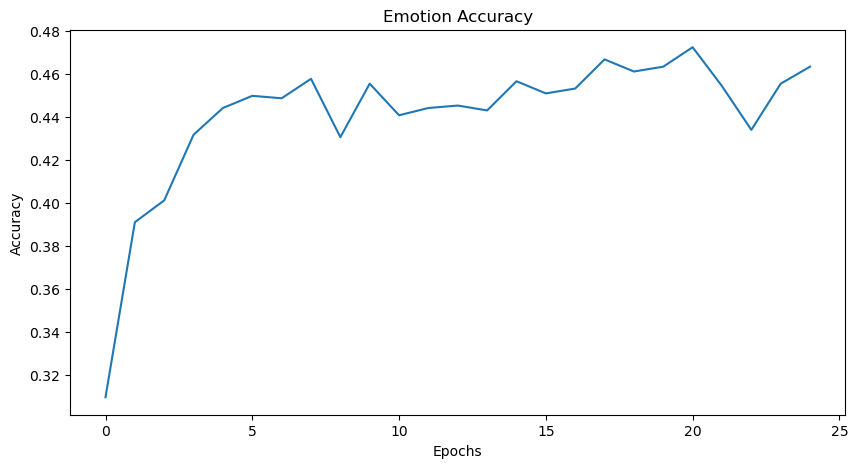

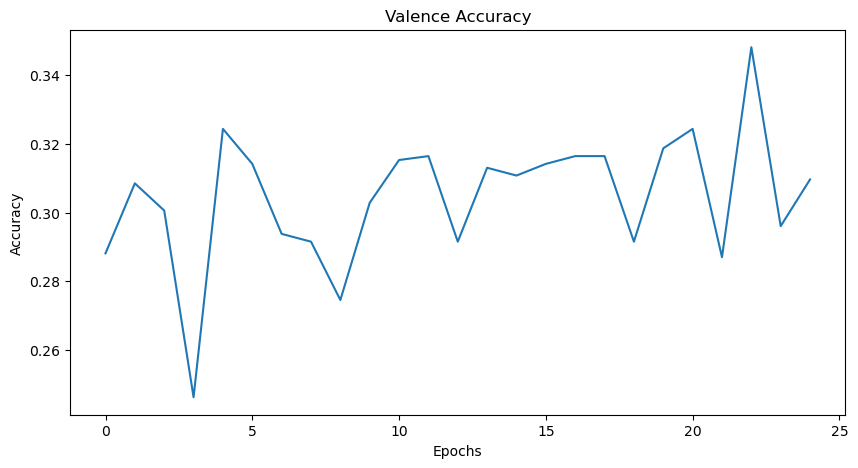

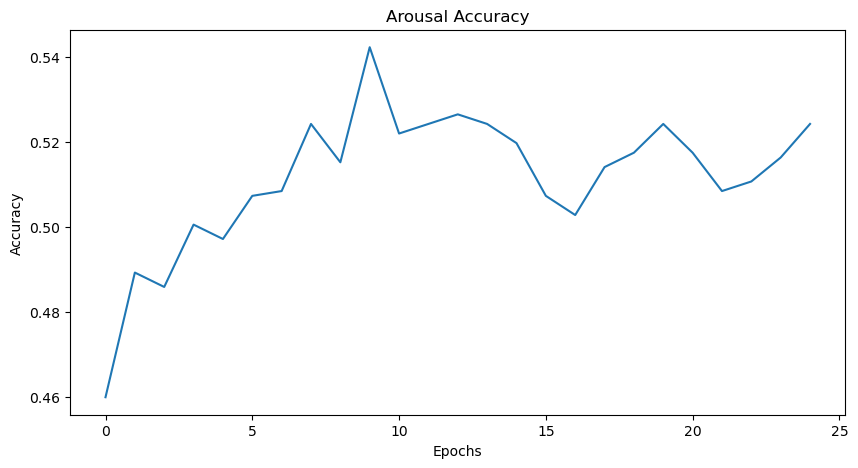

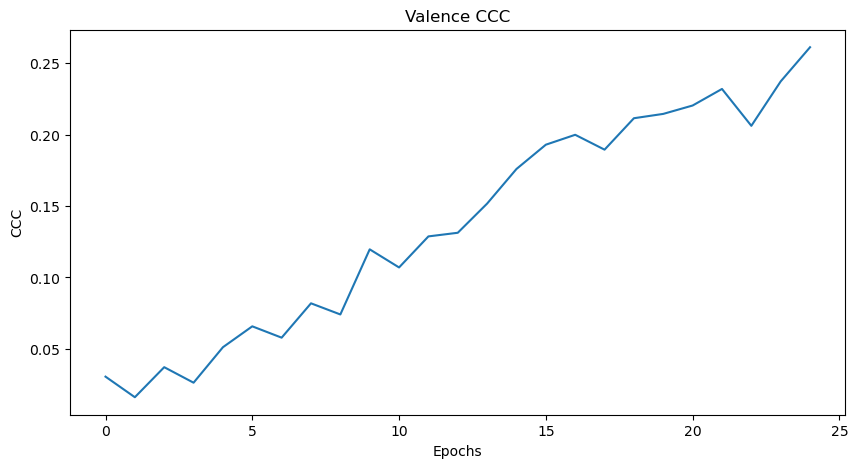

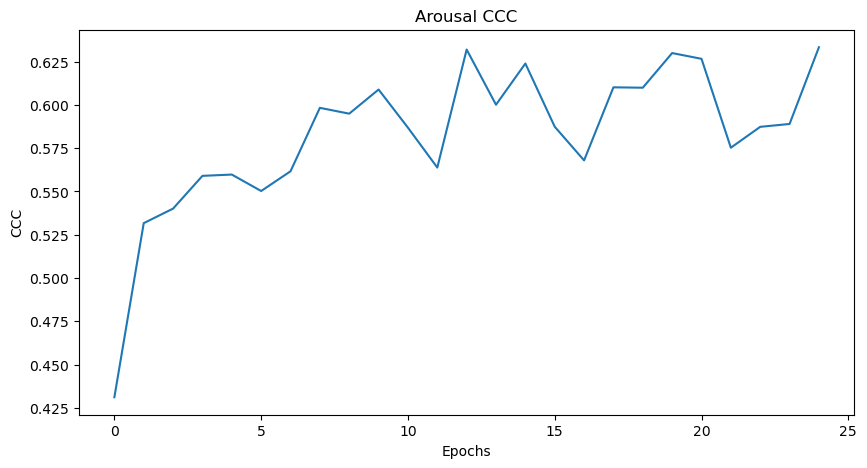

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Losses')
plt.legend()
plt.show()

# plot emotion accuracies
plt.figure(figsize=(10, 5))
plt.plot(emotion_accuracies, label='Emotion Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Emotion Accuracy')
plt.show()

# plot valence accuracies
plt.figure(figsize=(10, 5))
plt.plot(valence_accuracies, label='Valence Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Valence Accuracy')
plt.show()

# plot arousal accuracies
plt.figure(figsize=(10, 5))
plt.plot(arousal_accuracies, label='Arousal Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Arousal Accuracy')
plt.show()

# plot valence CCC
plt.figure(figsize=(10, 5))
plt.plot(valence_cccs, label='Valence CCC')
plt.xlabel('Epochs')
plt.ylabel('CCC')
plt.title('Valence CCC')
plt.show()

# plot arousal CCC
plt.figure(figsize=(10, 5))
plt.plot(arousal_cccs, label='Arousal CCC')
plt.xlabel('Epochs')
plt.ylabel('CCC')
plt.title('Arousal CCC')
plt.show()